# Урок 6 — Как измерить ошибку изображения

[План курса](../../README_ru.md) · [Предыдущий урок](lesson-05.ipynb) · [English](../en/lesson-06.ipynb) · [Следующий урок](lesson-07.ipynb)

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
from IPython.display import display

course_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "loss_demos.py").is_file()), None)
if course_root is None:
    raise FileNotFoundError("The notebook needs the complete course folder.")
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from loss_demos import (
    image_errors, gaussian_image, bell, center_loss,
    central_difference, numerical_gradient, descent_steps,
    loss_figure, loss_lab, tiny_loss_figure, equal_loss_figure,
    descent_figure, descent_lab, rates_figure, gradient_figure,
)
LANG = 'ru'


В первом блоке мы расставляли пятна вручную. Сдвигали центр, меняли цвет, смотрели на картинку. Теперь хочется передать эту работу программе. Но программа пока не знает, что означает «стало похоже».

Поставим рядом образец и наше изображение. В одном месте наше пятно слишком светлое, в другом — слишком тёмное. Из этих различий получится **функция ошибки**, или **loss**: правило, которое превращает две картинки в одно число. Меньшее число будет означать лучшее совпадение по выбранному правилу.

## 1. Пятно, образец и карта различий

У образца центр в $(1,0)$ и масштабы $1.2$ по обеим осям. Наше пятно начинает в $(-1,0)$. Оно рисуется на чёрном фоне, без других слоёв. Ползунок яркости $a$ умножает весь гауссов вес на число от 0 до 1. В этой простой сцене это может быть яркость белого пятна с непрозрачностью $a$.

Слева образец, в середине наш результат, справа различия между ними. Координаты и шкалы цвета закреплены. Сдвиг центра вправо к 1 постепенно убирает светлые области на карте ошибки. При совпавшем центре, но другой ширине остаётся кольцо различий. Одного центра недостаточно, чтобы совпала вся картинка.

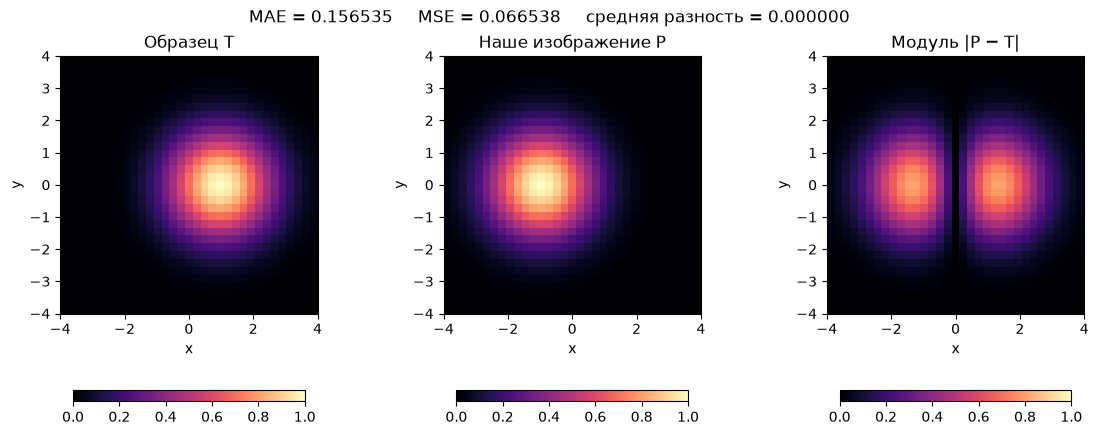

In [2]:
display(loss_figure(language=LANG))
display(loss_lab(language=LANG))

В карте «Со знаком» красное означает, что наш пиксель ярче образца, синее — темнее. Белое соответствует нулевой разности. В картах модуля и квадрата нулю соответствует тёмный цвет. Значит, светлая карта со знаком и тёмная карта модуля могут означать одно и то же полное совпадение.

Изображение здесь — таблица $33\times33$ чисел. Мы берём 33 координаты от −4 до 4 по каждой оси, включая края: всего $33\cdot33=1089$ отсчётов. Яркость нормирована: 0 — чёрный, 1 — белый. Это учебная сетка значений функции; пока без площади пикселя и сглаживания. Настройки образца закреплены, поэтому сравниваем один и тот же эталон при разных параметрах.

## 2. Четыре пикселя вместо целой картинки

Для ручного расчёта оставим четыре значения. $T$ — target, образец; $P$ — prediction, наше предсказанное изображение. Названия не обозначают специальные типы данных: обе картинки — обычные массивы одинакового размера.

$$
T=\begin{bmatrix}0&1\\0.5&0.5\end{bmatrix},\qquad
P=\begin{bmatrix}0.2&0.8\\0.1&0.9\end{bmatrix}.
$$

Вычитаем **значения на одинаковых местах**: верхнее левое из верхнего левого, а не из соседнего. Перестановка пикселей меняет картинку, даже если набор яркостей остаётся тем же.

[[ 0.2 -0.2]
 [-0.4  0.4]]


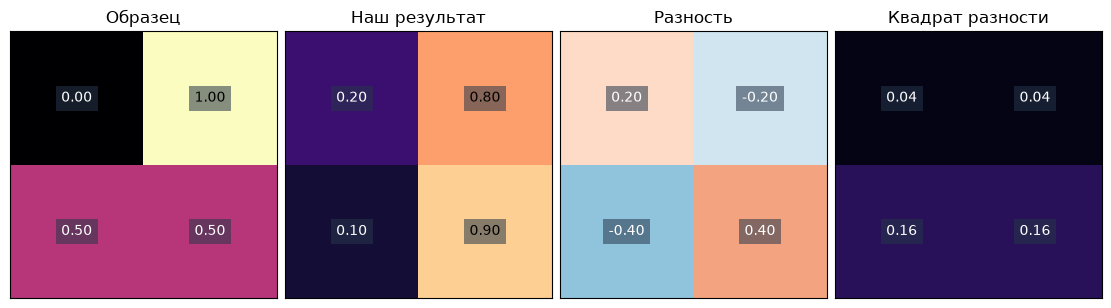

In [3]:
target = np.array([[0.0, 1.0], [0.5, 0.5]])
prediction = np.array([[0.2, 0.8], [0.1, 0.9]])
residual = prediction - target
print(residual)
display(tiny_loss_figure(language=LANG))

Назовём разность $r$ — residual, остаток. Для пикселя с номером $i$:

$$
r_i=P_i-T_i.
$$

Индекс $i$ — только номер. Если читать строки слева направо, получатся номера 1, 2, 3, 4. Формула требует два входа: яркость нашего пикселя $P_i$ и яркость соответствующего пикселя образца $T_i$. Выход $r_i$ может быть отрицательным.

| Пиксель | Наш P | Образец T | Разность P − T |
|---|---:|---:|---:|
| Верхний левый | 0.2 | 0 | 0.2 − 0 = 0.2 |
| Верхний правый | 0.8 | 1 | 0.8 − 1 = −0.2 |
| Нижний левый | 0.1 | 0.5 | 0.1 − 0.5 = −0.4 |
| Нижний правый | 0.9 | 0.5 | 0.9 − 0.5 = 0.4 |

Положительная разность — избыток яркости, отрицательная — недостаток. У каждого пикселя появился свой понятный сигнал. Но в итоге нам нужно одно число для всей картинки.

## 3. Почему обычная сумма обманывает

Средняя разность в нашем примере:

$$
\frac{0.2-0.2-0.4+0.4}{4}=\frac0{4}=0.
$$

Каждый пиксель ошибочен, а число уже равно нулю. Избытки и недостатки взаимно сократились. Средняя разность полезна для проверки общего смещения яркости: не стала ли вся картинка светлее. Но она не годится как единственная мера совпадения.

Нужно убрать возможность взаимного сокращения. Есть два простых способа: модуль и квадрат.

## 4. Модуль: сколько не хватает или сколько лишнего

Модуль — расстояние числа до нуля. Вертикальные черты $|r|$ означают, что отрицательное число берём без минуса, положительное оставляем прежним. Например, $|-0.4|=0.4$, $|0.2|=0.2$ и $|0|=0$.

Средняя абсолютная ошибка — **MAE**, mean absolute error:

$$
L_{\mathrm{MAE}}=\frac{0.2+0.2+0.4+0.4}{4}
=\frac{1.2}{4}=0.3.
$$

Буква $L$ — loss. Нижняя подпись лишь указывает, какое правило мы выбрали. Ошибка 0.3 означает: в среднем модуль разности яркости равен 0.3 на шкале от 0 до 1. Это не «30% неправильно расположенных пикселей» и не процент узнаваемости изображения.

Теперь короткая общая запись:

$$
L_{\mathrm{MAE}}=\frac1N\sum_{i=1}^{N}|P_i-T_i|.
$$

$N$ — количество сравниваемых чисел, здесь 4. Большой знак $\sum$, «сигма», означает сложение. Нижняя запись $i=1$ задаёт первый номер, верхняя $N$ — последний. Для каждого номера сначала вычитаем, затем берём модуль. После сложения всех модулей делим на $N$. Умножение на $1/N$ — то же деление на $N$.

## 5. Квадрат: большие промахи получают больший вес

Второй способ избавиться от знака — умножить разность саму на себя:

$$
(-0.4)^2=(-0.4)\cdot(-0.4)=0.16,\qquad
(0.2)^2=0.2\cdot0.2=0.04.
$$

Скобки важны: в квадрат возводится вся разность вместе с её знаком. Сначала вычитание, потом умножение, а не квадрат каждого изображения отдельно.

Средняя квадратичная ошибка — **MSE**, mean squared error:

$$
L_{\mathrm{MSE}}=\frac{0.04+0.04+0.16+0.16}{4}
=\frac{0.40}{4}=0.10.
$$

И общая формула:

$$
L_{\mathrm{MSE}}=\frac1N\sum_{i=1}^{N}(P_i-T_i)^2.
$$

Порядок действий тот же, но модуль заменён квадратом. Разность 0.4 вдвое больше 0.2. Её вклад в MAE тоже вдвое больше, а в MSE — вчетверо: $0.16/0.04=4$. Поэтому несколько больших промахов сильнее влияют на выбор параметров.

При этом $0.4^2=0.16$ **меньше** 0.4. Фраза «квадрат сильнее наказывает» относится к соотношению больших и малых ошибок внутри одного правила, а не к сравнению чисел MSE и MAE. Наши 0.1 и 0.3 измеряют разное; победителя между ними выбирать бессмысленно.

In [4]:
absolute = np.abs(residual)
squared = residual * residual
mae = absolute.sum() / residual.size
mse = squared.sum() / residual.size
print("absolute:", absolute)
print("squared:", squared)
print(f"MAE = {mae:.3f}; MSE = {mse:.3f}")
assert np.isclose(mae, 0.3)
assert np.isclose(mse, 0.1)

absolute: [[0.2 0.2]
 [0.4 0.4]]
squared: [[0.04 0.04]
 [0.16 0.16]]
MAE = 0.300; MSE = 0.100


И MAE, и MSE неотрицательны. Обе равны нулю только тогда, когда все сравниваемые числа совпали. Из этого не следует совпадение неизвестной 3D-сцены: пока проверено лишь изображение на выбранной сетке.

## 6. Почему среднее, а не сумма

Сумма квадратов у нас равна 0.4. Если дважды записать те же четыре пикселя, появятся восемь значений, а сумма вырастет до 0.8. Ничего не стало хуже, мы просто дважды посчитали одно и то же.

После деления на количество:

$$
\frac{0.4}{4}=0.1,\qquad\frac{0.8}{8}=0.1.
$$

Среднее сохраняет масштаб при точном повторении набора. Это удобно для разных размеров изображения. Но реальное изменение разрешения меняет выборку и детали, поэтому одинаковое значение ошибки между разными разрешениями само по себе ещё не гарантировано.

In [5]:
twice = image_errors(np.tile(prediction, (1, 2)), np.tile(target, (1, 2)))
print("numbers:", twice["count"], "MSE:", round(twice["mse"], 6))

numbers: 8 MSE: 0.1


## 7. У цветного пикселя три числа

В RGB красный, зелёный и синий каналы сравниваются отдельно. Например:

$$
T=(0.2,0.5,0.8),\qquad P=(0.4,0.2,0.8).
$$

Разности: $0.4-0.2=0.2$, $0.2-0.5=-0.3$, $0.8-0.8=0$. Один пиксель, но **три сравниваемых числа**:

$$
L_{\mathrm{MAE}}=\frac{0.2+0.3+0}{3}=\frac{0.5}{3}\approx0.166667,
$$

$$
L_{\mathrm{MSE}}=\frac{0.04+0.09+0}{3}=\frac{0.13}{3}\approx0.043333.
$$

Для изображения высотой $H$, шириной $W$ и числом каналов $C$ имеем $N=H\cdot W\cdot C$. Например, $2\cdot2\cdot3=12$ значений у картинки 2×2 в RGB. Высота и ширина — число строк и столбцов, $C=3$ для RGB и $C=1$ для серого изображения.

В NumPy вызов `mean()` без указания осей усредняет все элементы массива. Поэтому массив формы `(H, W, 3)` делится именно на $3HW$. Для карты ошибки удобно сначала усреднить квадраты по трём каналам каждого пикселя: останется карта `(H, W)`. Её среднее даст тот же общий MSE.

In [6]:
target_rgb = np.array([[[0.2, 0.5, 0.8]]])
prediction_rgb = np.array([[[0.4, 0.2, 0.8]]])
squared_rgb = (prediction_rgb - target_rgb) ** 2
pixel_map = squared_rgb.mean(axis=2)  # three channels -> one number per pixel
print("channel squares:", squared_rgb)
print("pixel map:", pixel_map)
print("MSE:", squared_rgb.mean())
assert np.isclose(pixel_map.mean(), squared_rgb.mean())

channel squares: [[[0.04 0.09 0.  ]]]
pixel map: [[0.04333333]]
MSE: 0.043333333333333335


Квадрат **средней подписанной разности каналов** дал бы другой ответ: красная и зелёная ошибки снова могли бы сократиться. Поэтому порядок «сначала квадрат каждого канала, потом среднее» здесь принципиален.

## 8. Что меняется на шкале от 0 до 255

Одна и та же нормированная яркость 0.2 соответствует $255\cdot0.2=51$ на шкале 0…255. Если умножить обе картинки на 255 без округления, все разности тоже умножатся на 255.

У MAE множитель останется 255. У MSE он попадёт под квадрат:

$$
(255r)^2=(255r)(255r)=255^2r^2=65025r^2.
$$

Для четырёх пикселей выше MAE станет $255\cdot0.3=76.5$, MSE — $65025\cdot0.1=6502.5$. Картинка та же, числа ошибки другие. При округлении до целых добавится небольшое отличие из-за квантования.

In [7]:
scaled = image_errors(255 * prediction, 255 * target)
print("MAE on 0..255:", scaled["mae"])
print("MSE on 0..255:", scaled["mse"])

MAE on 0..255: 76.5
MSE on 0..255: 6502.5


Обе картинки должны быть на одной шкале, с одинаковым порядком каналов и размером. Вычитание из `uint8` опасно: отрицательное значение может переполниться. Сначала переводим массив в число с плавающей точкой, например `image.astype(np.float64) / 255.0`, затем считаем разности.

И ещё одна отдельная вещь: деление на 255 меняет диапазон, но не превращает sRGB в линейный свет. Здесь и в проекте блока мы сравниваем нормированные значения изображения в одной выбранной кодировке. Физическую модель света таким действием не получаем.

## 9. Одно число теряет расположение ошибок

У чёрной картинки 8×8 есть два неудачных приближения. В первом все 64 значения равны 0.1. Во втором 63 значения нулевые, а одно равно 0.8.

$$
L_A=\frac{64\cdot0.1^2}{64}=0.01,\qquad
L_B=\frac{0.8^2}{64}=\frac{0.64}{64}=0.01.
$$

MSE одинаков, а вид совсем разный: слабая серая пелена против одного яркого пикселя. Формула честно посчитала своё правило. Просто она не хранит, где находятся ошибки и какие детали важны для смысла изображения.

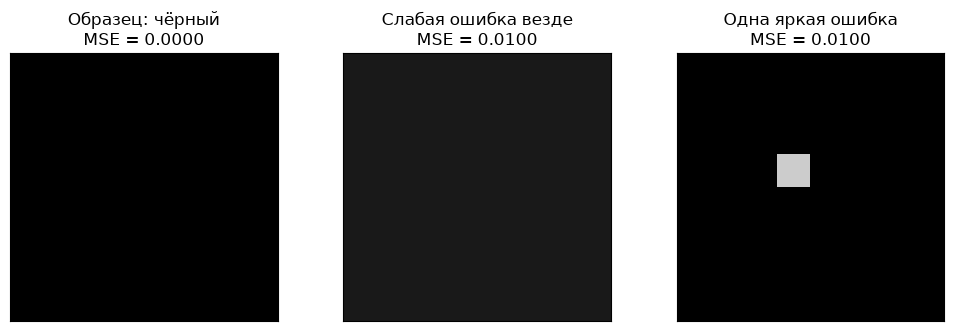

In [8]:
display(equal_loss_figure(language=LANG))

Поэтому рядом с числом остаются образец, результат и карта различий. Низкая ошибка не доказывает хорошую геометрию, правильную резкость или совпадение на новых ракурсах. А небольшой сдвиг резкого края может дать заметную попиксельную ошибку при похожем общем виде.

## 10. Небольшие опыты

**Полное совпадение.** В первом опыте центр переходит в 1, ширина остаётся 1.2, яркость 1. Как изменятся обе ошибки и три режима карты?

<details>
<summary>Разбор</summary>

Каждый пиксель совпадает: $P_i-T_i=0$. Модули и квадраты нулевые, MAE и MSE равны нулю. Карта со знаком белая, две неотрицательные карты тёмные. Различие цветов связано с выбранной шкалой, а не с разными ошибками.

</details>

**Один большой промах.** Четыре модуля ошибок в варианте A равны $(0.2,0.2,0.2,0.2)$, в варианте B — $(0.8,0,0,0)$. Какая функция различит варианты?

<details>
<summary>Разбор</summary>

У обоих MAE равна $0.8/4=0.2$. MSE у A равна $(4\cdot0.04)/4=0.04$, у B — $0.64/4=0.16$. Одинаковая сумма модулей распределена по-разному: квадрат предпочитает четыре малых промаха одному большому.

</details>

**Только красный.** В картинке 2×2 RGB все значения совпали, кроме красного канала одного пикселя: он отличается на 0.6. Чему равен общий MSE?

<details>
<summary>Разбор</summary>

Всего $2\cdot2\cdot3=12$ значений. Один квадрат равен $0.6^2=0.36$, остальные нулевые. MSE равна $0.36/12=0.03$. Деление на четыре дало бы 0.09 — это средняя сумма квадратов по пикселям, другое соглашение. Оба правила возможны, но в этом курсе усредняем и каналы.

</details>

Теперь у каждого набора параметров есть число ошибки. Но это число ещё не говорит, куда сдвинуть центр и насколько. В [следующем уроке](lesson-07.ipynb) изменим параметр совсем чуть-чуть и посмотрим, что произойдёт с ошибкой. Из этого опыта вырастет производная.